# Семинар 5. Напряжённо-деформированное состояние пластины с круглым отверстием

**Плоское напряжённое состояние · линейный треугольный элемент · метод конечных элементов · решение Кирша**

**Цель:** самостоятельно построить конечно-элементную модель четверти пластины с отверстием, определить перемещения и напряжения, а затем сопоставить распределения напряжений с аналитическим решением Кирша.

В предыдущих семинарах по теплопроводности неизвестной была одна температура в каждом узле. Теперь неизвестны **две компоненты перемещения**: $u_x$ и $u_y$. Общая последовательность МКЭ сохраняется: аппроксимация на элементе → локальная матрица → глобальная система → граничные условия → решение → восстановление напряжений.

**Последовательность расчёта:**

1. Подготовить геометрию, сетку и группы границ в Gmsh.
2. Записать уравнения плоской теории упругости и получить матрицы $\mathbf D$, $\mathbf B_e$, $\mathbf K_e$.
3. Собрать систему $\mathbf K\mathbf U=\mathbf F$, задать закрепления и внешнюю нагрузку.
4. Получить поля $u_x$, $u_y$, $\sigma_x$, $\sigma_y$, $\tau_{xy}$.
5. Вычислить полярные компоненты напряжений и сравнить их с решением Кирша.

Все величины в вычислениях задаются в **СИ** (м, Н, Па). Преобразование единиц для вывода на графики оговаривается отдельно. Ноутбук содержит полностью записанный исполняемый код: учебные пояснения сопровождают именно эти ячейки, без предполагаемых `TODO`.

## 1. Подготовка окружения и исходных данных

Используются `numpy` (матрицы и линейная алгебра), `matplotlib` (графики), Python API `gmsh` (геометрия, сетка, физические группы), а также стандартные модули `json` и `pathlib`.

**Для воспроизведения** нужен установленный модуль `gmsh` и исходный файл `_geom/kirsch.xao`, в котором заданы геометрия пластины и именованные **Physical Groups**. Ячейка ниже задаёт относительные пути к исходной геометрии и создаваемой сетке `_geom/kirsch.msh`. Запись путей с обратной косой чертой рассчитана на Windows; запускать ноутбук нужно из каталога проекта, относительно которого определены эти пути.

Без исходного XAO-файла ноутбук нельзя выполнить с нуля: один только код не восстанавливает физические группы и геометрию. В последующих ячейках никакие CSV или JSON сетки не импортируются — данные извлекаются непосредственно из открытой модели Gmsh.

In [1]:
## для экспорта словаря
import json
## работа с матрицами, математика
import numpy as np
## отображение и графики
import matplotlib.pyplot as plt
## работа с геометрией и сеткой
import gmsh
from pathlib import Path

In [2]:
# Подготовленная геометрия с именованными граничными участками.
# Имя файла можно изменить, если XAO сохранён под другим названием.
geo_file = Path(r"_geom\kirsch.xao")
# Сгенерированная сетка и массивы для основного расчёта.
mesh_path = Path(r"_geom\kirsch.msh")

## 2. Постановка задачи и геометрия

Рассмотрим однородную тонкую квадратную пластину с центральным круглым отверстием, растягиваемую вдоль оси $x$. Из-за симметрии геометрии и нагрузки достаточно моделировать четверть области:

$$
\Omega=\{(x,y):0\leq x\leq L,\;0\leq y\leq L,\; x^2+y^2\geq R^2\}.
$$

Здесь $L=0{,}10$ м — размер четверти пластины вдоль каждой оси, $R=0{,}020$ м — радиус отверстия. Толщина $t$ считается постоянной.

Это **двумерная плоская задача упругости**, а **не осесимметричная задача**: в интегралах жёсткости нет множителя $2\pi r$.

<p align="center">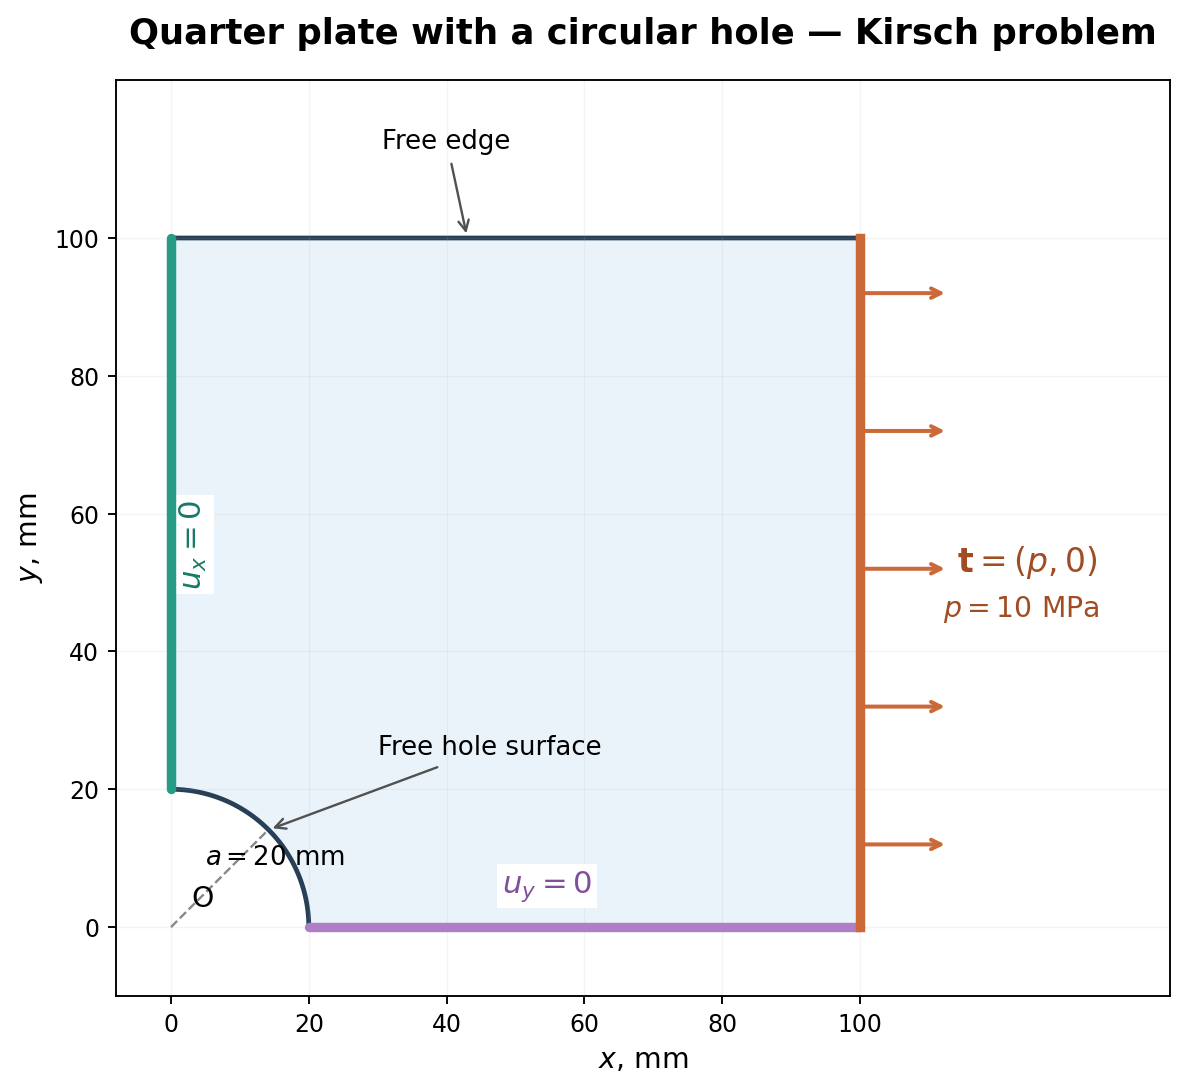</p>

<p align="center"><em>Рис. 1. Расчётная четверть пластины и механические граничные условия.</em></p>

### 2.1. Механические граничные условия

Для четверти пластины задаются:

| Участок | Условие | Физический смысл |
|---|---|---|
| Левая вертикальная граница $x=0$ (`SymX`) | $u_x=0$ | Запрет перемещения по нормали к оси симметрии; $u_y$ свободно |
| Нижняя горизонтальная граница $y=0$ (`SymY`) | $u_y=0$ | Запрет нормального перемещения; $u_x$ свободно |
| Правая граница $x=L$ (`pressure`) | $\mathbf t=(p,0)$ | Равномерное растяжение вправо |
| Верхняя граница $y=L$ | $\mathbf t=\mathbf 0$ | Свободная поверхность |
| Контур отверстия $r=R$ | $\mathbf t=\mathbf 0$ | Свободная поверхность отверстия |

Здесь $\mathbf t=\boldsymbol\sigma\mathbf n$ — **вектор поверхностной нагрузки** (Па). Несмотря на имя группы `pressure` и функции `bc_pressure`, на правой границе задаётся постоянная **декартова компонента растягивающей нагрузки**, а не давление на контур отверстия.

Параметры, используемые ниже:

| Обозначение | Значение | В коде |
|---|---:|---|
| $L$ | 0,10 м | `L_domain` |
| $R$ | 0,020 м | `R_hole` (для аналитики — `R`) |
| $p$ | 10 МПа | `p_load` |
| $E$ | 210 ГПа | `E` |
| $\nu$ | 0,30 | `nu` |
| $t$ | 0,005 м | `th` |

В отличие от исходного `kirsch.m`, здесь приняты $E=210$ ГПа и $t=5$ мм. При линейной упругости, однородном материале, нулевых заданных перемещениях и заданном **напряжении** $p$ изменение $E$ меняет масштаб перемещений, а не напряжений.

### 2.2. Построение сетки

Ниже Gmsh открывает подготовленную геометрию, генерирует линейные треугольники с максимальным размером около 10 мм и записывает файл `kirsch.msh`. Наличие Physical Groups в исходной геометрии необходимо для последующего задания нагрузки и закреплений.

In [3]:
gmsh.initialize()
gmsh.open(str(geo_file))
# Создание сетки и сохранение в файл
h = 0.01                                         # Размер сетки, м
gmsh.option.setNumber("Mesh.MeshSizeMax", h)
gmsh.option.setNumber("Mesh.ElementOrder", 1)
# Двумерная сетка для осесимметричной задачи
gmsh.model.mesh.generate(2)
mesh_path.parent.mkdir(parents=True, exist_ok=True)
gmsh.write(str(mesh_path))

In [4]:
# Читаем уже сгенерированную сетку
gmsh.clear()
gmsh.open(str(mesh_path))

## 3. Математическая модель плоской упругости

### 3.1. Перемещения, деформации и равновесие

Искомые функции — компоненты вектора перемещений:

$$
\mathbf u=\begin{bmatrix}u_x\\u_y\end{bmatrix},\qquad
\boldsymbol\varepsilon=\begin{bmatrix}\varepsilon_x\\\varepsilon_y\\\gamma_{xy}\end{bmatrix}
=\begin{bmatrix}
\partial u_x/\partial x\\
\partial u_y/\partial y\\
\partial u_x/\partial y+\partial u_y/\partial x
\end{bmatrix}.
$$

В третьей компоненте используется **инженерная сдвиговая деформация** $\gamma_{xy}=2\varepsilon_{xy}$.

При отсутствии объёмных сил дифференциальные уравнения равновесия имеют вид

$$
\frac{\partial\sigma_x}{\partial x}+\frac{\partial\tau_{xy}}{\partial y}=0,\qquad
\frac{\partial\tau_{xy}}{\partial x}+\frac{\partial\sigma_y}{\partial y}=0.
$$

### 3.2. Плоское напряжённое состояние

Для тонкой пластины принимаем $\sigma_z=\tau_{xz}=\tau_{yz}=0$. Закон Гука для изотропного материала:

$$
\boldsymbol\sigma=\mathbf D\boldsymbol\varepsilon,\qquad
\boldsymbol\sigma=\begin{bmatrix}\sigma_x\\\sigma_y\\\tau_{xy}\end{bmatrix},\qquad
\boxed{\mathbf D=\frac{E}{1-\nu^2}
\begin{bmatrix}1&\nu&0\\\nu&1&0\\0&0&(1-\nu)/2\end{bmatrix}}.
$$

Матрица $\mathbf D$ имеет размер $3\times3$ и размерность Па. Для **плоской деформации** использовалась бы другая матрица $\mathbf D$.

### 3.3. Вариационная постановка

Рассматриваем линейную статическую задачу без объёмных сил и температурных деформаций. Полная потенциальная энергия:

$$
\Pi(\mathbf u)=
\frac12\int_{\Omega} \boldsymbol\varepsilon^{\mathsf T}\mathbf D
\boldsymbol\varepsilon\,t\,dA
-\int_{\Gamma_t}\mathbf u^{\mathsf T}\mathbf t\,t\,d\Gamma.
$$

Первый интеграл — энергия деформации; второй — работа внешней распределённой нагрузки со знаком минус. После конечно-элементной аппроксимации и условия стационарности $\delta\Pi=0$ получаем:

$$
\Pi(\mathbf U)=\tfrac12\mathbf U^{\mathsf T}\mathbf K\mathbf U
-\mathbf U^{\mathsf T}\mathbf F,\qquad
\boxed{\mathbf K\mathbf U=\mathbf F}.
$$

Если в сетке $N$ узлов, то глобальный вектор содержит $2N$ перемещений, а $\mathbf K$ имеет размер $2N\times2N$.

**Связь с предыдущими семинарами:** принцип сборки такой же, как в теплопроводности, но теперь у каждого узла две степени свободы вместо одной.

## 4. Получение сетки и групп границ

### 4.1. Подготовка сетки Gmsh

В предыдущих исполняемых ячейках ноутбук открывает `_geom/kirsch.xao`, строит **двумерную сетку линейных элементов** с заданным максимальным характерным размером `h=0.01` м и записывает её в `_geom/kirsch.msh`. Затем очищает текущую модель и открывает записанную сетку.

> Комментарий «для осесимметричной задачи» внутри исполняемой ячейки генерации остался от другой работы. **Здесь решается плоская задача**, без осесимметричного множителя.

### 4.2. Чтение координат и связности

Из Gmsh непосредственно извлекаются:

- `pnts` — координаты узлов, массив `(nn, 2)`, **в метрах**;
- `elms` — индексы трёх вершин каждого линейного треугольника, массив `(ne, 3)`;
- `nn` и `ne` — количество узлов и элементов.

Код вычитает единицу из тегов элементов Gmsh, переходя к нумерации Python с нуля. При этом он **предполагает**, что теги узлов последовательны, начинаются с 1 и соответствуют строкам массива `pnts`; для произвольного файла Gmsh такое соответствие необходимо проверять отдельно. Здесь используется заранее подготовленная модель.

In [5]:
node_tags, pnts, _ = gmsh.model.mesh.getNodes()
pnts = pnts.reshape(-1, 3)                            
# Для 2D задачи оставляем x, y
pnts = pnts[:, :2]

In [6]:
_, _, elms = gmsh.model.mesh.getElements(2)
elms = elms[0].reshape(-1, 3)
elms = elms - 1

In [7]:
# сохраним количество элементов, чтобы потом можно было писать циклы по ним
nn = len(pnts)
ne = len(elms) 

### 4.3. Выделение физических групп и проверка сетки

Для каждой одномерной физической группы функция `getNodesForPhysicalGroup()` возвращает узлы границы. Далее два вспомогательных алгоритма находят:

- `elements` — треугольники, у которых **ровно две** вершины принадлежат выбранной группе;
- `edges` — соответствующие пары вершин граничных рёбер;
- `length` — длины этих рёбер в метрах.

В итоге `boundary[имя_группы]` содержит словарь с ключами `nodes`, `elements`, `edges`, `length`. Важно, чтобы имена `SymX`, `SymY` и `pressure` действительно присутствовали в исходной модели: именно они используются в ячейках задания граничных условий.

**Ограничение метода выделения рёбер:** условие «ровно две вершины из группы» рассчитано на эту подготовленную треугольную сетку; для произвольной геометрии и более сложной разметки границ нужно явно проверять полноту и отсутствие повторов рёбер.

На следующем рисунке проверяем положение сетки и групп: `SymX` должна лежать на $x=0$, `SymY` — на $y=0$, `pressure` — на $x=L$; контур отверстия должен оставаться ненагруженным.

In [8]:
def sel_elms(elms, sel_nds):
    sel_elms = []
    for el in range(ne):
        n = np.isin(elms[el], sel_nds).sum()
        if n == 2:
            sel_elms.append(el)
    return np.array(sel_elms, dtype=int) 

In [9]:
def sel_edges(elms, sel_elms, sel_nds):
    edges = []
    for el in sel_elms:
        edge = elms[el][np.isin(elms[el], sel_nds)]
        edges.append(edge)
    return np.array(edges, dtype=int) 

In [10]:
boundary = {}
for dim, tag in gmsh.model.getPhysicalGroups(1):
    name  = gmsh.model.getPhysicalName(dim, tag)
    nodes, _ = gmsh.model.mesh.getNodesForPhysicalGroup(dim, tag)
    nodes = nodes - 1
    elements = sel_elms(elms, nodes)
    edges = sel_edges(elms, elements, nodes)
    
    L = []
    for nd1, nd2 in edges:
        L.append(np.linalg.norm(pnts[nd2] - pnts[nd1]))
    L = np.array(L)
    boundary[name] = {
            'nodes': np.asarray(nodes, dtype=np.int64),
            'elements': np.asarray(elements, dtype=np.int64),
            'edges': edges,
            'length': L
        }

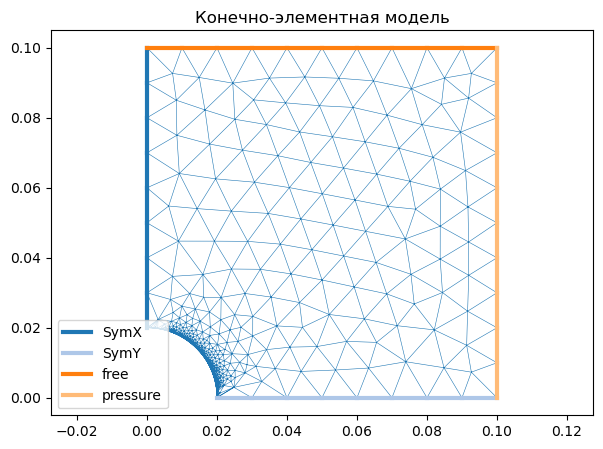

In [11]:
# Отображение всех физических групп
colors = plt.get_cmap("tab20").colors
# картинка
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Конечно-элементная модель')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms, linewidth=0.4)
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='lower left')
plt.show()

## 5. Линейный треугольный элемент (CST)

### 5.1. Аппроксимация перемещений

Для треугольника с вершинами $i,j,m$ линейные функции формы $N_i,N_j,N_m$ задают перемещения:

$$
\mathbf u(x,y)=\sum_{k\in\{i,j,m\}}N_k(x,y)
\begin{bmatrix}u_{x,k}\\u_{y,k}\end{bmatrix},\qquad
\mathbf U_e=\begin{bmatrix}u_{x,i}&u_{y,i}&u_{x,j}&u_{y,j}&u_{x,m}&u_{y,m}\end{bmatrix}^{\mathsf T}.
$$

В линейном треугольнике производные функций формы постоянны, поэтому **деформации и напряжения постоянны внутри элемента**.

### 5.2. Матрица связи деформаций с перемещениями

Обозначим ориентированную площадь треугольника $A_e^{or}$:

$$
2A_e^{or}=(x_j-x_i)(y_m-y_i)-(y_j-y_i)(x_m-x_i),
\qquad A_e=|A_e^{or}|.
$$

Пусть $b_i=y_j-y_m$, $b_j=y_m-y_i$, $b_m=y_i-y_j$, а
$c_i=x_m-x_j$, $c_j=x_i-x_m$, $c_m=x_j-x_i$. Тогда

$$
\boldsymbol\varepsilon_e=\mathbf B_e\mathbf U_e,\qquad
\boxed{\mathbf B_e=\frac{1}{2A_e^{or}}
\begin{bmatrix}
b_i&0&b_j&0&b_m&0\\
0&c_i&0&c_j&0&c_m\\
c_i&b_i&c_j&b_j&c_m&b_m
\end{bmatrix}}.
$$

В **текущей функции `get_kel()`** в знаменателе используется положительная площадь `area`, а не ориентированная. Это эквивалентно формуле выше **при одинаковой положительной ориентации всех треугольников** ($A_e^{or}>0$), характерной для корректно ориентированной исходной сетки. Если в другой сетке встречаются треугольники с обратным порядком вершин, знаки восстановленных деформаций и напряжений будут ошибочными; код здесь не изменяется.

### 5.3. Элементная матрица жёсткости

Матрица $\mathbf D$ определяется свойствами материала, а $\mathbf B_e$ — координатами вершин элемента. При постоянной толщине и однородном материале:

$$
\boxed{\mathbf K_e= t A_e\mathbf B_e^{\mathsf T}\mathbf D\mathbf B_e},
\qquad [\mathbf K_e]=\text{Н/м},
$$

где $\mathbf K_e$ имеет размер $6\times6$. Функция `get_kel(element)` возвращает **пару** `(Kel, B)`; при сборке используется `Kel`, при расчёте напряжений — `B`.

In [12]:
# Исходные данные (СИ)
L_domain = 0.10        # м
R_hole = 0.020         # м
p_load = 10e6          # Па
E = 210e9              # Па
nu = 0.30              # -
th = 0.005             # м

In [13]:
# Матрица упругих свойств (плоское напряжённое состояние)
D = E / (1 - nu**2) * np.array([
    [1,  nu, 0],
    [nu, 1,  0],
    [0,  0,  (1 - nu) / 2]])  

In [14]:
# Обозначим функцию для создания локальных(элементных) матриц жесткости
def get_kel(element, th=th):
    i , j , m = element
    xi, yi = pnts[i]
    xj, yj = pnts[j]
    xm, ym = pnts[m]
    area = 0.5 * abs((xj-xi)*(ym-yi) - (yj-yi)*(xm-xi))
    # Матрица связи деформаций с узловыми перемещениями
    bi, bj, bm =  yj-ym, ym-yi, yi-yj
    ci, cj, cm =  xm-xj, xi-xm, xj-xi
    B = 1 / (2 *area) * np.array([
            [bi,  0,   bj,   0,   bm,   0 ],
            [0,   ci,  0,    cj,  0,    cm],
            [ci,  bi,  cj,   bj,  cm,   bm]])
    Kel = th  * area * B.T @ D @ B                                      # используем не поэлементное умножение, а матричное
    return Kel, B   

### 5.4. Проверка элемента

Элементная матрица жёсткости для линейного треугольника должна быть симметричной и иметь размер $6\times6$. Для жёсткого поступательного перемещения все деформации равны нулю; поэтому суммы строк $\mathbf K_e$ близки к нулю (с учётом округления).

В следующей ячейке выводятся симметрия, суммы строк и коэффициенты $\mathbf K_e$ первого элемента. У невырожденного CST-элемента при обычной линейной упругости есть **три нулевые моды жёсткого движения** (два переноса и один поворот); до задания закреплений это не означает ошибку.

In [15]:
Ke0, _ = get_kel(elms[0])
print('Симметрична:', np.allclose(Ke0, Ke0.T))
print('Суммы строк (должны быть близки к 0):', Ke0.sum(axis=1))
print("Матрица жесткости Ke (6×6):")
for row in Ke0:
    print(" ".join(f"{v:12.3e}" for v in row))

Симметрична: True
Суммы строк (должны быть близки к 0): [ 1.93715096e-07 -1.49011612e-08 -1.56462193e-07 -1.93715096e-07
 -2.98023224e-08  0.00000000e+00]
Матрица жесткости Ke (6×6):
   1.676e+09   -5.374e+08   -1.252e+09    5.391e+08   -4.247e+08   -1.678e+06
  -5.374e+08    9.817e+08    5.679e+08   -9.827e+08   -3.052e+07    1.009e+06
  -1.252e+09    5.679e+08    1.004e+09   -5.047e+08    2.476e+08   -6.326e+07
   5.391e+08   -9.827e+08   -5.047e+08    1.102e+09   -3.441e+07   -1.197e+08
  -4.247e+08   -3.052e+07    2.476e+08   -3.441e+07    1.771e+08    6.493e+07
  -1.678e+06    1.009e+06   -6.326e+07   -1.197e+08    6.493e+07    1.187e+08


## 6. Сборка глобальной системы

Для $N=\texttt{nn}$ узлов вводим вектор перемещений с чередованием компонент:

$$
\mathbf U=\begin{bmatrix}u_{x,0}&u_{y,0}&u_{x,1}&u_{y,1}&\ldots\end{bmatrix}^{\mathsf T}.
$$

Для элемента $e=(i,j,m)$ его глобальные индексы:

```python
IndX = [2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1]
```

Каждая $\mathbf K_e$ добавляется в соответствующий блок глобальной матрицы:

$$\mathbf K[\mathrm{IndX},\mathrm{IndX}]\mathrel{+}=\mathbf K_e.$$

В **этой реализации** `Kglob` и `Fglob` создаются как **плотные** массивы NumPy (`np.zeros`), а выбор блока производится через `np.ix_`. Это удобно на учебной сетке, но при большом числе узлов потребует больше памяти, чем разреженное хранение. Начальный вектор $\mathbf F$ нулевой; внешняя нагрузка будет добавлена позднее.

После сборки `plt.spy(Kglob)` показывает ненулевую структуру глобальной матрицы — расположение связей между степенями свободы элементов.

In [16]:
Kglob  = np.zeros([2*nn, 2*nn])
Fglob = np.zeros(2*nn)

In [17]:
# чтобы сформировать подмассив по выбранным индексам нужно использовать np.ix_
for el in range(ne):
    # по сравнению с прошлым разом придется развернуть, чтобы учесть что в каждом узле две неизвестных (записанных в матрице подряд)
    i, j, m =elms[el]
    # Индексы шести степеней свободы элемента
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1], dtype=int)             # индексы должны быть целочисленные
    # Добавляем элементную матрицу в глобальную
    IndXArr = np.ix_(IndX, IndX)
    Kel, _ = get_kel(elms[el])
    Kglob[IndXArr] += Kel    

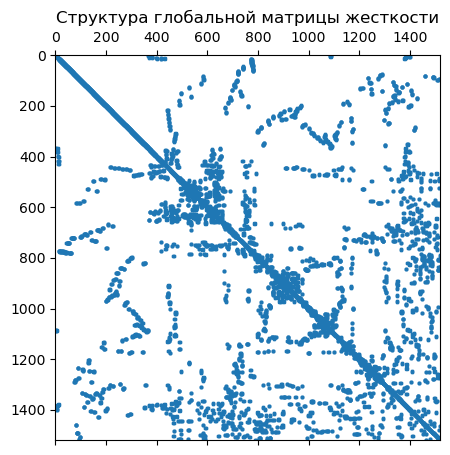

In [18]:
plt.figure(figsize=(5, 5))
plt.spy(Kglob, markersize=2)
plt.title('Структура глобальной матрицы жесткости')
plt.show()

## 7. Граничные условия

### 7.1. Условия I рода: перемещения на осях симметрии

На вертикальной оси $x=0$ задаём $u_x=0$, на горизонтальной оси $y=0$ — $u_y=0$. Запрет обеих компонент на каждой линии привёл бы к искусственному закреплению.

Функция `bc_disp(K, F, boundary, ux, uy)` использует **замену уравнений** для закреплённых степеней свободы: соответствующая строка матрицы обнуляется, диагональный элемент становится единицей, а правая часть равна заданному перемещению. Не заданная компонента пропускается благодаря значению `np.nan`.

$$
K_{q,:}=0,\qquad K_{q,q}=1,\qquad F_q=\overline u_q.
$$

**Важно:** в текущем коде обнуляются **только строки**, а столбцы сохраняются. Поэтому после закрепления `K1` обычно **несимметрична**, хотя исходная `Kglob` симметрична. Для используемого прямого решателя `np.linalg.solve` такая запись допустима и принуждает нужные перемещения. Это **не** метод выделения свободных степеней свободы и **не** симметричная модификация матрицы — именно такой алгоритм фактически реализован ниже.

In [19]:
def bc_disp(K, F, boundary, ux=np.nan, uy=np.nan):
    for nd in boundary['nodes']:
        # Ограничение перемещения по X
        if not np.isnan(ux):
            idx = 2*nd
            K[idx, :] = 0
            K[idx, idx] = 1
            F[idx] = ux
        # Ограничение перемещения по Y
        if not np.isnan(uy):
            idx = 2 * nd + 1
            K[idx, :] = 0
            K[idx, idx] = 1
            F[idx] = uy
    return K, F

### 7.2. Условия II рода: распределённая нагрузка

На правой границе задан вектор поверхностной нагрузки $\mathbf t=(p,0)^{\mathsf T}$ в Па. Для ребра $(i,j)$ длиной $\ell$ эквивалентный вектор узловых сил получают из виртуальной работы:

$$
\mathbf F_{\Gamma,e}=
 t\int_{\Gamma_e}\mathbf N^{\mathsf T}\mathbf t\,d\Gamma
 =\boxed{\frac{t\ell}{2}
\begin{bmatrix}p_x\\p_y\\p_x\\p_y\end{bmatrix}}.
$$

Две вершины получают по половине суммарной силы на ребре. Размерность согласуется: $\mathrm{Па}\cdot\mathrm{м}\cdot\mathrm{м}=\mathrm{Н}$.

Функция `bc_pressure()` проходит по `boundary['edges']` и `boundary['length']`, добавляя этот вектор в **правую часть**. Матрица жёсткости не меняется. Поскольку на верхнем краю и отверстии нагрузка нулевая, для них добавлять вектор сил не требуется.

**Почему здесь не вычисляется нормаль к ребру?** В этом семинаре нагрузка заранее известна в глобальных координатах: $p_x=p$, $p_y=0$ на вертикальной правой границе. Поэтому можно непосредственно интегрировать заданный **вектор тяги**. Для произвольного контура с нормальным давлением пришлось бы рассчитывать нормаль к каждому ребру и переводить скалярное давление в компоненты вектора нагрузки; функция `bc_pressure()` этого не делает.

In [20]:
def bc_pressure(F, boundary, px=0, py=0, th=th):
    edges = boundary['edges']
    L = boundary['length']
    for (i, j), length in zip(edges, L):
        IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1], dtype=int)
        F[IndX] += th * length / 2 * np.array([px, py, px, py])
    return F 

### 7.3. Применение условий и решение СЛАУ

Порядок ячеек ниже соответствует действующему коду:

1. Создать копии собранных `Kglob`, `Fglob`.
2. Вызвать `bc_disp()` для `SymX` **с `ux=0`** и для `SymY` **с `uy=0`**.
3. Добавить растяжение через `bc_pressure(..., boundary['pressure'], px=p_load)`.
4. Решить $\mathbf K_1\mathbf U=\mathbf F_1$ функцией `np.linalg.solve`.

Комментарии внутри ячейки с закреплениями ошибочно описывают компоненты `ux/uy`, но **сами вызовы верны**: определяющими являются аргументы функций. В этой задаче нагруженная правая грань не совпадает с закреплёнными степенями свободы, поэтому применение сил **после** закреплений не изменяет их предписанные значения. Для общей постановки обычно сначала собирают все нагрузки, затем обрабатывают закрепления.

Вычисленный `Disp` — вектор длины $2\,\texttt{nn}$ в **метрах**. Матрица `Disp2plot = Disp.reshape(-1, 2).T` размера `(2, nn)` собирает в первой строке $u_x$, во второй — $u_y$.

In [21]:
K1 = Kglob.copy()
F1 = Fglob.copy()

In [22]:
## ГУ симметрии
# Симметрия относительно X: uy = 0
K1, F1 = bc_disp(K1, F1, boundary["SymX"], ux=0)
# Симметрия относительно Y: ux = 0
K1, F1 = bc_disp(K1, F1, boundary["SymY"], uy=0)

In [23]:
## ГУ давление
# Растяжение правой границы напряжением 10 МПа
F1 = bc_pressure(F1, boundary["pressure"], px=p_load, py=0, th=th)

In [24]:
Disp = np.linalg.solve(K1, F1)
# Преобразование вектора перемещений в матрицу 2 × nn
Disp2plot = Disp.reshape(-1, 2).T

## 8. Поля перемещений

После решения глобальной системы массив `Disp2plot` содержит две строки перемещений. Выделим $u_x$, $u_y$ и модуль:

$$u=\sqrt{u_x^2+u_y^2}.$$

Все три компоненты **в вычислениях выражены в метрах**. Следующая ячейка выводит их непосредственно, без преобразования в миллиметры (несмотря на подписи «мм» на рисунке).

In [25]:
## отобразим результаты

In [26]:
# Компоненты и модуль перемещения
Ux = Disp2plot[0, :]
Uy = Disp2plot[1, :]
U  = np.sqrt(Ux**2 + Uy**2)

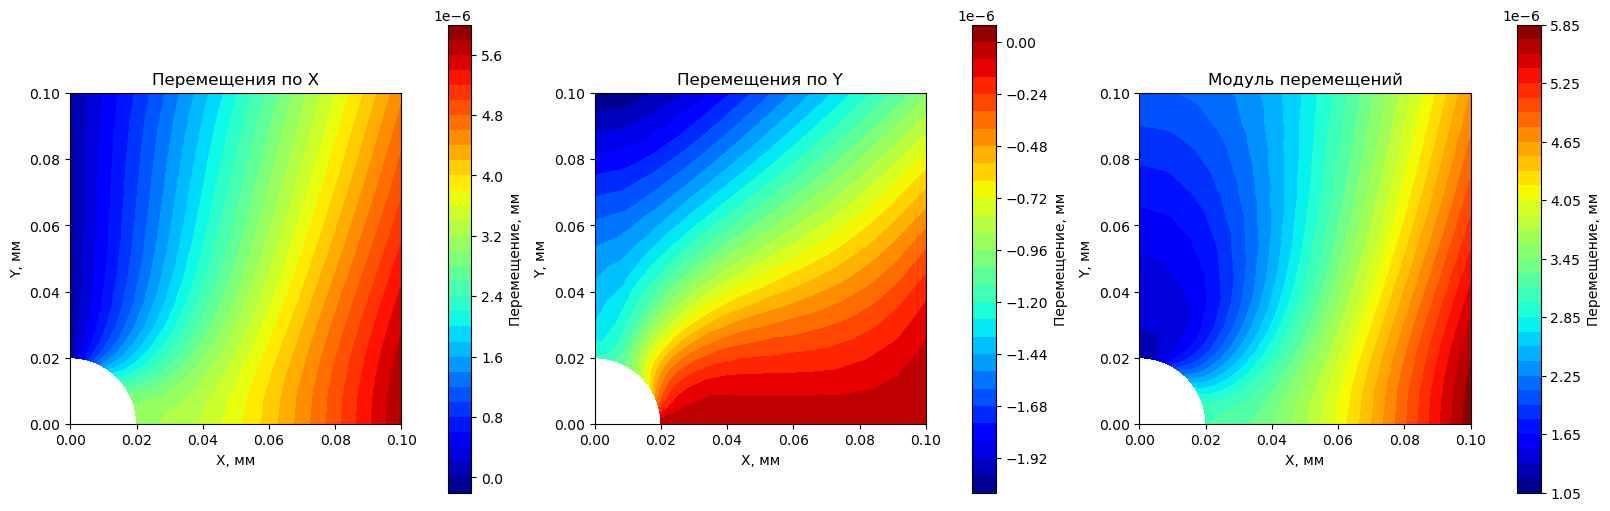

In [27]:
fields = [
    (Ux, "Перемещения по X"),
    (Uy, "Перемещения по Y"),
    (U, "Модуль перемещений")
]

fig, axs = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

for ax, (values, title) in zip(axs, fields):
    im = ax.tricontourf(
        pnts[:, 0], pnts[:, 1],
        elms, values,
        levels=30, cmap='jet'
    )

    fig.colorbar(im, ax=ax, label='Перемещение, мм')
    ax.set_aspect('equal')
    ax.set_xlabel('X, мм')
    ax.set_ylabel('Y, мм')
    ax.set_title(title)

plt.show()

## 9. Восстановление напряжений

### 9.1. Деформации и напряжения в элементах

Глобальная система даёт **узловые перемещения**, а напряжения вычисляются для каждого элемента из его шести степеней свободы:

$$
\boldsymbol\varepsilon_e=\mathbf B_e\mathbf U_e,\qquad
\boxed{\boldsymbol\sigma_e=\mathbf D\mathbf B_e\mathbf U_e}.
$$

Здесь `_, B = get_kel(elms[el])` повторно получает матрицу $\mathbf B_e$, а матрица жёсткости игнорируется. Массив `Sigma` имеет форму `(ne, 3)`; его столбцы — $\sigma_x$, $\sigma_y$, $\tau_{xy}$ **в Па**.

Для линейного треугольного элемента (CST) деформации и напряжения **постоянны внутри каждого треугольника**. Такие поэлементные значения могут различаться на общем ребре соседних элементов; поэтому для гладкой цветовой карты ниже будет выполнено узловое усреднение.

In [28]:
# Напряжения в конечных элементах
Sigma = np.zeros((ne, 3))

for el in range(ne):
    i, j, m = elms[el]

    # Матрица связи деформаций с перемещениями
    _, B = get_kel(elms[el])

    # Перемещения узлов элемента
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1],  dtype=int)
    Uel = Disp[IndX]

    # Деформации и напряжения
    Eps = B @ Uel
    Sigma[el] = D @ Eps

### 9.2. Узловое усреднение для визуализации

Чтобы построить непрерывно выглядящую цветовую карту, код усредняет напряжения элементов, примыкающих к каждому узлу:

$$
\overline{\boldsymbol\sigma}_i
=\frac{1}{n_i}\sum_{e\,\ni\,i}\boldsymbol\sigma_e,
$$

где $n_i$ — число треугольников, содержащих узел $i$. В коде счётчик — `count`, а результат — `SX`, `SY`, `SXY`, соответственно $\overline\sigma_x$, $\overline\sigma_y$, $\overline\tau_{xy}$. Это **арифметическое, невзвешенное по площадям** усреднение: оно предназначено для постобработки и сглаживает экстремумы вблизи отверстия. Оно **не** участвует в решении СЛАУ.

In [29]:
# Суммы напряжений в узлах
sigmaX_sum = np.zeros(nn)
sigmaY_sum = np.zeros(nn)
sigmaXY_sum = np.zeros(nn)
count = np.zeros(nn)

for el in range(ne):
    nodes = elms[el]

    sigmaX_sum[nodes] += Sigma[el, 0]
    sigmaY_sum[nodes] += Sigma[el, 1]
    sigmaXY_sum[nodes] += Sigma[el, 2]
    count[nodes] += 1

# Усреднение напряжений
SX = sigmaX_sum / count
SY = sigmaY_sum / count
SXY = sigmaXY_sum / count

### 9.3. Карты узловых декартовых напряжений

Три массива `SX`, `SY`, `SXY` задают соответственно $\overline\sigma_x$, $\overline\sigma_y$, $\overline\tau_{xy}$ **в Па**. `tricontourf` интерполирует эти узловые величины на треугольниках для отображения. В исполняемой ячейке подписи легенд/заголовки остались от графика перемещений и **не соответствуют содержимому** — это отдельно зафиксировано в разделе 11.

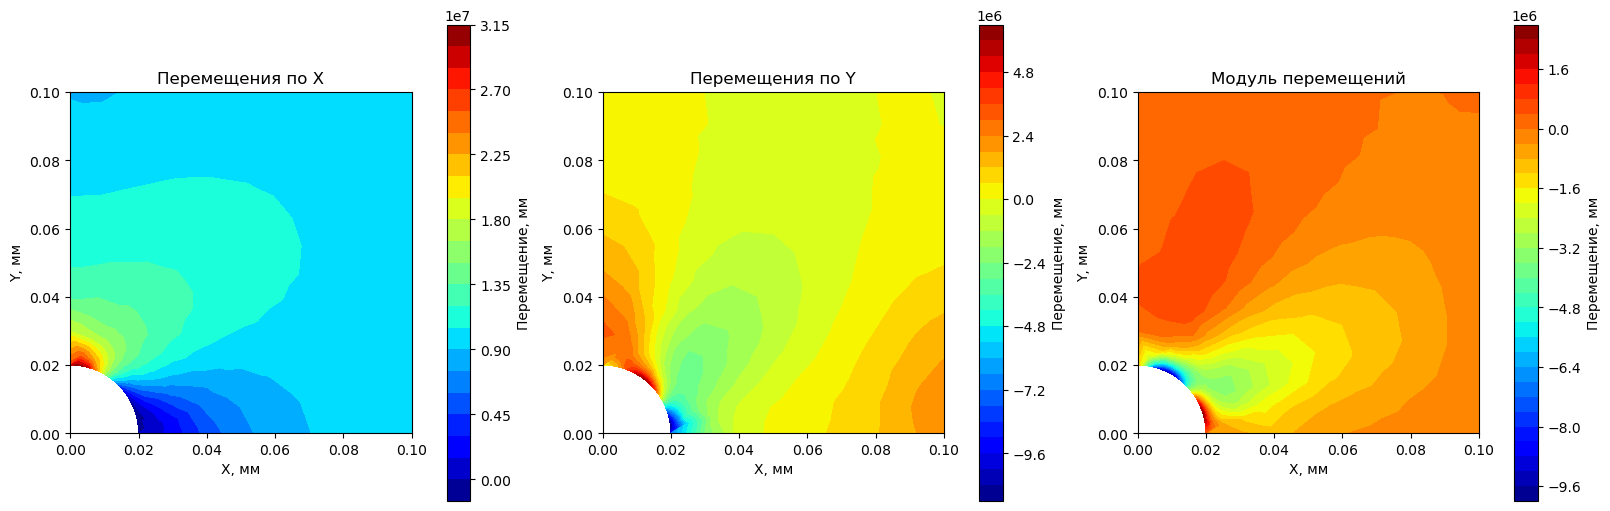

In [30]:
fields = [
    (SX,  "Перемещения по X"),
    (SY,  "Перемещения по Y"),
    (SXY, "Модуль перемещений")
]

fig, axs = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

for ax, (values, title) in zip(axs, fields):
    im = ax.tricontourf(
        pnts[:, 0], pnts[:, 1],
        elms, values,
        levels=30, cmap='jet'
    )

    fig.colorbar(im, ax=ax, label='Перемещение, мм')
    ax.set_aspect('equal')
    ax.set_xlabel('X, мм')
    ax.set_ylabel('Y, мм')
    ax.set_title(title)

plt.show()

## 10. Полярные напряжения и сравнение с решением Кирша

Для круглого отверстия наиболее показательны напряжения в радиальном и окружном направлениях. На свободном контуре отверстия в точном решении выполняется $\sigma_{rr}=0$ и $\tau_{r\theta}=0$; окружное $\sigma_{\theta\theta}$ определяет концентрацию напряжений.

### 10.1. Полярные координаты узлов

Для каждой **узловой** точки $(x_i,y_i)$ относительно центра отверстия $(0,0)$ вычисляем

$$
r_i=\sqrt{x_i^2+y_i^2},\qquad \theta_i=\operatorname{atan2}(y_i,x_i).
$$

Массивы `r` и `theta` имеют длину `nn`. Координаты нужны дважды: для вычисления аналитических напряжений Кирша и для поворота численных напряжений МКЭ. Поскольку область содержит отверстие радиуса $R>0$, в корректной сетке нет узлов с $r=0$ и деление на $r$ допустимо.

In [31]:
# Полярные координаты узлов
x, y = pnts[:, 0], pnts[:, 1]

r = np.sqrt(x**2 + y**2)
theta = np.arctan2(y, x)

### 10.2. Аналитическое решение Кирша

Для **бесконечной** упругой пластины с круглым свободным отверстием радиуса $R$ и однородным удалённым растяжением $p$ вдоль оси $x$ напряжения в полярной системе имеют вид:

$$
\boxed{\sigma_{rr}^{K}=
\frac p2\left[1-\frac{R^2}{r^2}+
\left(1-4\frac{R^2}{r^2}+3\frac{R^4}{r^4}\right)\cos(2\theta)\right]},
$$

$$
\boxed{\sigma_{\theta\theta}^{K}=
\frac p2\left[1+\frac{R^2}{r^2}-
\left(1+3\frac{R^4}{r^4}\right)\cos(2\theta)\right]},
$$

$$
\boxed{\tau_{r\theta}^{K}=
-\frac p2\left[1+2\frac{R^2}{r^2}-3\frac{R^4}{r^4}\right]\sin(2\theta)}.
$$

При $r=R$ выполняются $\sigma_{rr}^{K}=0$, $\tau_{r\theta}^{K}=0$, а

$$
\sigma_{\theta\theta}^{K}(R,\theta)=p\bigl(1-2\cos(2\theta)\bigr).
$$

Отсюда при $\theta=90^\circ$:

$$
\boxed{\sigma_{\theta\theta,\max}^{K}=3p=30\,\text{МПа}},
\qquad \boxed{K_t^{K}=\sigma_{\max}^{K}/p=3}.
$$

**Принципиальное ограничение сравнения.** Решение Кирша относится к бесконечной области, тогда как в МКЭ рассматривается конечная четверть пластины ($L/R=5$) с заданным постоянным растяжением только на правой границе и свободным верхним краем. На внешнем контуре напряжения Кирша вообще говоря **не совпадают** с этими граничными условиями. Поэтому численные поля не обязаны точно совпадать с аналитическими даже при идеальной сетке. Значение 30 МПа — **эталон бесконечной пластины**, не гарантированный результат нашей конечной области.

В следующей ячейке теоретические компоненты `sigma_rr_K`, `sigma_tt_K`, `sigma_rt_K` вычисляются **в узлах МКЭ**, в Па.

In [32]:
# Параметры задачи Кирша
R = 0.02       # Радиус отверстия, м
p = p_load     # Растягивающее напряжение, Па

# Аналитические напряжения
sigma_rr_K = p/2 * (
    1 - (R/r)**2 +
    (1 - 4*(R/r)**2 + 3*(R/r)**4)*np.cos(2*theta)
)

sigma_tt_K = p/2 * (
    1 + (R/r)**2 -
    (1 + 3*(R/r)**4)*np.cos(2*theta)
)

sigma_rt_K = -p/2 * (
    1 + 2*(R/r)**2 - 3*(R/r)**4
)*np.sin(2*theta)


### 10.3. Преобразование узловых напряжений МКЭ

После усреднения напряжения доступны в декартовой системе координат: `SX`, `SY`, `SXY`. Для их сравнения с решением Кирша поворачиваем тензор напряжений на угол $\theta$:

$$
\boldsymbol\sigma_{polar}=\mathbf Q^{\mathsf T}\boldsymbol\sigma_{cart}\mathbf Q,\qquad
\mathbf Q=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}.
$$

В компонентах:

$$
\begin{aligned}
\sigma_{rr}&=\sigma_x\cos^2\theta+\sigma_y\sin^2\theta
+2\tau_{xy}\sin\theta\cos\theta,\\[3pt]
\sigma_{\theta\theta}&=\sigma_x\sin^2\theta+\sigma_y\cos^2\theta
-2\tau_{xy}\sin\theta\cos\theta,\\[3pt]
\tau_{r\theta}&=(\sigma_y-\sigma_x)\sin\theta\cos\theta
+\tau_{xy}(\cos^2\theta-\sin^2\theta).
\end{aligned}
$$

В **этом** ноутбуке переход выполняется **в узлах**, а не в центрах треугольников: массивы `SX`, `SY`, `SXY`, `theta` имеют одинаковую длину `nn`. Сначала усредняются декартовы компоненты напряжений, затем тензор поворачивается по координатам узла. Итоговые массивы — `sigma_rr`, `sigma_tt`, `sigma_rt` в Па.

Сначала вычислим значения $\cos\theta$ и $\sin\theta$ для всех узлов, затем применим приведённые формулы. Переход в полярную систему нужен **для интерпретации и сравнения**, а не для решения глобальной СЛАУ: сам МКЭ-расчёт выполнен в декартовых координатах.

In [33]:
c = np.cos(theta)
s = np.sin(theta)

# Полярные напряжения (МКЭ)
sigma_rr = SX*c**2 + SY*s**2 + 2*SXY*s*c

sigma_tt = SX*s**2 + SY*c**2 - 2*SXY*s*c

sigma_rt = (SY-SX)*s*c + SXY*(c**2-s**2)


### 10.4. Сравнение на одинаковых шкалах

Для каждой из трёх полярных компонент строятся две карты: слева поле МКЭ, справа аналитика Кирша. Границы цветовой шкалы выбираются общими **внутри каждой пары**, а напряжения переводятся из Па в МПа делением на $10^6$. Это визуальное сопоставление **узловых** значений, а не проверка совпадения полных краевых задач.

Координаты `pnts` передаются в метрах; подписи осей «мм» в существующей ячейке ошибочны и оставлены без изменения.

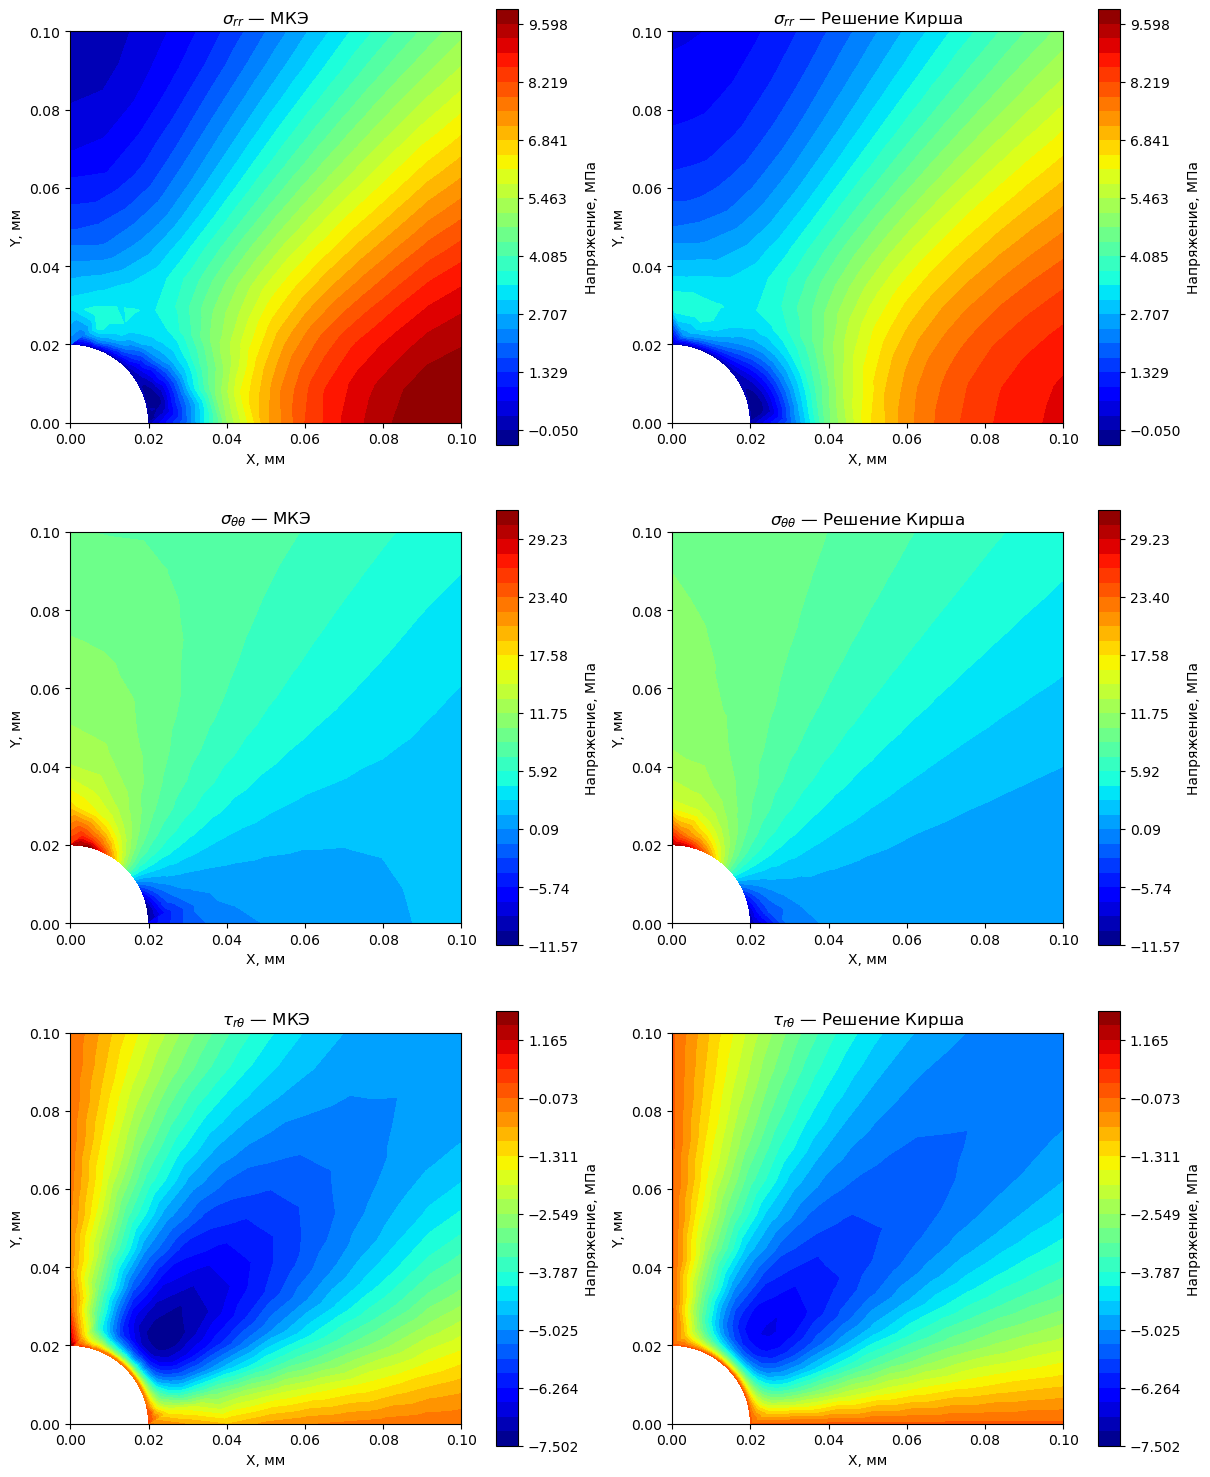

In [34]:

fields = [
    (sigma_rr, sigma_rr_K, r'$\sigma_{rr}$'),
    (sigma_tt, sigma_tt_K, r'$\sigma_{\theta\theta}$'),
    (sigma_rt, sigma_rt_K, r'$\tau_{r\theta}$')
]

fig, axs = plt.subplots(3, 2, figsize=(12, 15),
                        constrained_layout=True)

for row, (fem, theory, name) in enumerate(fields):

    # Одинаковая цветовая шкала для МКЭ и аналитики
    vmin = min(fem.min(), theory.min()) / 1e6
    vmax = max(fem.max(), theory.max()) / 1e6
    levels = np.linspace(vmin, vmax, 31)

    for col, (values, method) in enumerate([
        (fem, 'МКЭ'),
        (theory, 'Решение Кирша')
    ]):
        ax = axs[row, col]

        im = ax.tricontourf(
            pnts[:, 0], pnts[:, 1],
            elms, values/1e6,
            levels=levels, cmap='jet'
        )

        fig.colorbar(im, ax=ax, label='Напряжение, МПа')

        ax.set_aspect('equal')
        ax.set_xlabel('X, мм')
        ax.set_ylabel('Y, мм')
        ax.set_title(f'{name} — {method}')

plt.show()


## 11. Анализ результатов и контроль воспроизводимости

### 11.1. Сопоставление полей

Итоговая фигура содержит **три пары карт**: радиальные $\sigma_{rr}$, окружные $\sigma_{\theta\theta}$ и касательные $\tau_{r\theta}$ напряжения. Слева в каждой паре — МКЭ после узлового усреднения, справа — формулы Кирша в тех же узлах. Для каждой пары используется **единая шкала в МПа** (`values/1e6`), поэтому различия видны непосредственно.

На контуре отверстия в предельном аналитическом решении должны выполняться $\sigma_{rr}=\tau_{r\theta}=0$ и максимум $\sigma_{\theta\theta}=3p$ при $\theta=\pi/2$. В МКЭ на точность влияют конечные размеры пластины, сетка, линейный порядок элементов и узловое усреднение. По цветовым полям можно оценить характер концентрации, но **значение численного $K_t$ текущий исполняемый код отдельно не вычисляет**.

### 11.2. Важные замечания к подписям существующих графиков

Исполняемые ячейки намеренно оставлены **без изменений**. При чтении полученных изображений учитывайте следующие особенности их подписей:

- **График перемещений:** `pnts` и `Ux`, `Uy`, `U` выводятся **в метрах**, несмотря на подписи осей и шкалы «мм». На самой диаграмме значения не умножены на 1000.
- **График декартовых напряжений:** на нём фактически отображаются `SX`, `SY`, `SXY` **в Па**, хотя подписи и заголовки ошибочно остались от графика перемещений («Перемещение, мм», «Модуль перемещений»).
- **Сравнение с Киршем:** компоненты напряжений правильно переводятся в **МПа** делением на `1e6`; однако координаты осей также передаются из `pnts` в **метрах**, несмотря на подписи «мм».

Это **ошибки представления единиц на графиках**, а не преобразования самих численных полей; они отмечены здесь, потому что менять исполняемые ячейки не требуется.

### 11.3. Что проверить при воспроизведении

1. В каталоге проекта доступен `_geom/kirsch.xao`, а Gmsh загружает три нужные группы (`SymX`, `SymY`, `pressure`) и строит линейные треугольники.
2. Теги узлов соответствуют индексации `pnts`, все `elms` допустимы, элементы невырожденные и ориентированы одинаково; функции выделения рёбер не пропускают нагруженную границу.
3. Вызовы `bc_disp()` действительно задают **$u_x=0$ при $x=0$ и $u_y=0$ при $y=0$**. Исходная `Kglob` симметрична; матрица **после** замены строк может быть несимметрична.
4. Полная сила на правой стороне длиной $L$ при постоянной тяге $p$ должна равняться $F_x=ptL=10^7\cdot0{,}005\cdot0{,}10=5000$ Н, $F_y=0$ (если группа `pressure` включает всю правую сторону).
5. Размеры массивов согласованы: `Disp` — $(2\,nn,)$, `Sigma` — $(ne,3)$, `SX/SY/SXY` и полярные компоненты — по `nn` значений. Сравнение с аналитикой проводится в одних и тех же узлах.

### 11.4. Вопросы для обсуждения

1. Почему в теплопроводности у узла одна степень свободы, а здесь две? Как это влияет на размер $\mathbf K_e$?
2. Почему на границе симметрии нельзя закреплять одновременно $u_x$ и $u_y$?
3. Чем нагрузка в виде заданной тяги $\mathbf t$ отличается от давления по нормали к произвольному контуру?
4. Почему CST-элемент даёт постоянные напряжения, а узловое усреднение их сглаживает?
5. Почему решение Кирша при $K_t=3$ не обязано точно воспроизводиться на конечном квадрате?
6. Как повлияют размер сетки у отверстия и порядок аппроксимации на максимум окружных напряжений?

**Для отчёта:** приложить сетку с границами, поля перемещений и декартовых напряжений, три пары полярных полей МКЭ/Кирш; пояснить причины различий. Если требуется **численное значение** коэффициента концентрации $K_t$ или проверка равновесия по реакциям опор, нужны дополнительные вычисления — в текущих ячейках они не реализованы.

### Использованные материалы

- `chaynoff-fea.pdf`, § 2.4.2, с. 57–61 — постановка двумерной линейной упругости, элементные соотношения и сборка жёсткости.
- `kirsch.m`, `bc_mech.m` — исходная MATLAB-логика расчёта и приложения граничной нагрузки.
- `theory.m` — формулы аналитического решения Кирша.
- Материалы предыдущих семинаров по теплопроводности — линейные треугольные элементы и принципы глобальной сборки.